In [2]:
import os
import sys
import re
project_root = "/mnt/c/Users/Advait/Documents/Imperial/Year_4/Final_Year_Project/final-project"
sys.path.insert(0, project_root)
os.chdir(project_root)
from matplotlib import pyplot as plt
import pandas as pd
from Bio import SeqIO
from statistics import mean
from collections import Counter
import math
from dataclasses import dataclass
from main.scripts.constants import TEST_DATA
import matplotlib.pyplot as plt

In [3]:

def plot_loss_curve(log_file,out_file):
    df = pd.read_csv(log_file)
    plt.figure(figsize=(10, 5))
    plt.plot(df['num_steps'], df['ema_train_loss'], label='Train Loss', color='blue')
    plt.plot(df['num_steps'], df['ema_val_loss'], label='Validation Loss', color='orange')
    plt.xlabel('Number of Steps')
    plt.ylabel('Loss (EMA)')
    plt.title('Training and Validation Loss vs Number of Steps')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(out_file, format="svg")
    plt.show()

def plot_accuracy_curve(log_file,out_file):
    df = pd.read_csv(log_file)
    plt.figure(figsize=(10, 5))
    plt.plot(df['num_steps'], df['ema_train_acc'], label='Train Read Accuracy', color='blue')
    plt.plot(df['num_steps'], df['ema_val_acc'], label='Validation Read Accuracy', color='orange')
    plt.xlabel('Number of Steps')
    plt.ylabel('Read Accuracy (EMA)')
    plt.title('Training and Validation Accuracy vs Number of Steps')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(out_file, format="svg")
    plt.show()

def count_repeated_sequences(s):
    repeated_groups = re.findall(r'(.)\1{1,}', s)
    return len(repeated_groups)

def homopolymers_per_sequence(basecall_file, eval_df):
    alignment_ids = set(eval_df["Query ID"])
    succ_homopoolymers= []
    fail_homopolymers = []
    for rec in SeqIO.parse(basecall_file,"fastq"):
        if str(rec.id) in alignment_ids:
            succ_homopoolymers.append(count_repeated_sequences(str(rec.seq)))
        else:
            fail_homopolymers.append(count_repeated_sequences(str(rec.seq)))
    return mean(succ_homopoolymers), mean(fail_homopolymers)

def get_avg_reads_length(basecall_file, eval_df):
    alignment_ids = set(eval_df["Query ID"])
    succ_lens= []
    fail_lens = []
    for rec in SeqIO.parse(basecall_file,"fastq"):
        if str(rec.id) in alignment_ids:
            succ_lens.append(len(str(rec.seq)))
        else:
            fail_lens.append(len(str(rec.seq)))
    
    return mean(succ_lens),mean(fail_lens)

def kl(counter):
    KL = 0
    total = sum(counter.values())
    for k,v in counter.items():
        KL += (v/total) * math.log((v/total)/0.25)
    
    return KL

def get_average_kl(basecall_file,eval_df):
    alignment_ids = set(eval_df["Query ID"])
    succ_kls = []
    fail_kls = []
    for rec in SeqIO.parse(basecall_file,"fastq"):
        if str(rec.id) in alignment_ids:
            succ_kls.append(kl(Counter(str(rec.seq))))
        else:
            fail_kls.append(kl(Counter(str(rec.seq))))
    return mean(succ_kls),mean(fail_kls)

def generate_results(result_dirs, columns,is_wick=False,**kwargs):
    output_lines = {}
    for i,f in enumerate(result_dirs):
        for g in os.listdir(f):
            if is_wick and g not in TEST_DATA:
                continue
            basecall_file = os.path.join(f,g,"basecalls.fastq")
            alignment_stats_df = (pd.read_csv(os.path.join(f,g,"evaluation","alignment_stats.csv")))
            has_eval=False
            if alignment_stats_df.iloc[0]["Aligned Reads"] != 0:
                has_eval = True
                eval_df = (pd.read_csv(os.path.join(f,g,"evaluation","evaluation.csv")))
            basecall_stats_df = (pd.read_csv(os.path.join(f,g,"basecall_stats.csv")))

            failed_basecalls = len(basecall_stats_df[basecall_stats_df["Read Succeeded"] == 0])
            alignment_row = alignment_stats_df.iloc[0]
            alignment_rate = alignment_row["Aligned Reads"]/(alignment_row["Aligned Reads"] + alignment_row["Failed alignments"] + failed_basecalls)
            consensus_accuracy = ""
            payload_accuracy = ""
            if os.path.isfile(os.path.join(f,g,"evaluation","consensus_accuracy.csv")):
                consensus_accuracy = pd.read_csv(os.path.join(f,g,"evaluation","consensus_accuracy.csv"))["Consensus Accuracy"].item()
            if os.path.isfile(os.path.join(f,g,"payload_accuracy.txt")):
                with open(os.path.join(f,g,"payload_accuracy.txt"), "r") as pf:
                    payload_accuracy=float(pf.read())
            results = {
                "Name": (lambda _: g,""),
                "Median Read Accuracy": (lambda _: eval_df["Accuracy"].median()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Median Match Rate": (lambda _: eval_df["Match Rate"].median()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Median Mismatch Rate": (lambda _: eval_df["Mismatch Rate"].median()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Median Insertion Rate": (lambda _: eval_df["Insertion Rate"].median()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Median Deletion Rate": (lambda _: eval_df["Deletion Rate"].median()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Mean Read Accuracy": (lambda _: eval_df["Accuracy"].mean()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Mean Match Rate": (lambda _: eval_df["Match Rate"].mean()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Mean Mismatch Rate": (lambda _: eval_df["Mismatch Rate"].mean()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Mean Insertion Rate": (lambda _: eval_df["Insertion Rate"].mean()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Mean Deletion Rate": (lambda _: eval_df["Deletion Rate"].mean()*100,".2f") if has_eval else (lambda _: "N/A",""),
                "Alignment Success Rate": (lambda _: alignment_rate*100,".2f"),
                "Mean Homopolymers Success": (lambda _: homopolymers_per_sequence(basecall_file, eval_df)[0],".2f") if has_eval else (lambda _: "N/A",""),
                "Mean Homopolymers Fail": (lambda _: homopolymers_per_sequence(basecall_file, eval_df)[1],".2f") if has_eval else (lambda _: "N/A",""),   
                "Mean Length Success": (lambda _: get_avg_reads_length(basecall_file, eval_df)[0],".2f") if has_eval else (lambda _: "N/A",""),
                "Mean Length Fail": (lambda _: get_avg_reads_length(basecall_file, eval_df)[1],".2f") if has_eval else (lambda _: "N/A",""),
                "Mean KL Success": (lambda _: get_average_kl(basecall_file, eval_df)[0],".4f") if has_eval else (lambda _: "N/A",""),
                "Mean KL Fail": (lambda _: get_average_kl(basecall_file, eval_df)[1],".4f") if has_eval else (lambda _: "N/A",""),
                "Consensus Accuracy": (lambda _: consensus_accuracy*100,".2f"),
                "Payload Accuracy": (lambda _: payload_accuracy*100,".2f"),
                "Reads": (lambda _: len(basecall_stats_df),"")
            }
            latex_items = []
            for j,c in enumerate(columns):
                if c in results:
                    concat = format(results[c][0](None),results[c][1])
                else:
                    concat = str(kwargs[c][i])
                latex_items.append(concat)
            if g in output_lines:
                output_lines[g].append(latex_items)
            else:
                output_lines[g] = [latex_items]
    return output_lines

@dataclass
class FormattingOptions:
    multirow: bool
    row_colours: dict[int,str]
    midrule: bool

folder_name_to_file = {"EBI":"EBI.jp2",
                       "MLK_excerpt_VBR_45-85":"MLK_excerpt_VBR_45-85.mp3",
                       "View_huff3.cd":"View_huff3.cd",
                       "watsoncrick":"watsoncrick.pdf",
                       "wssnt10":"wssnt10.txt"}

def generate_latex(output_lines,formatting_options):
    latex_str = ""
    for idx,(k,v) in enumerate(output_lines.items()):
        for i,row in enumerate(v):
            for j,item in enumerate(row):
                if item in folder_name_to_file:
                    item = folder_name_to_file[item]
                if i == 0 and j==0 and formatting_options.multirow:
                    concat = f"\\multirow{{{len(v)}}}{{*}}{{{item}}}"
                elif i!=0 and j==0 and formatting_options.multirow:
                    concat = ""
                else:
                    concat = item
                if j==0 and i in formatting_options.row_colours and not formatting_options.multirow:
                    concat+=f" \\rowcolor{{{formatting_options.row_colours[i]}}}"
                elif i in formatting_options.row_colours and formatting_options.multirow and j!=0:
                    concat+= f"\\cellcolor{{{formatting_options.row_colours[i]}}}"
                latex_str += concat
                if j < len(row) - 1:
                    latex_str += " & "
            latex_str += " \\\\\n"
        if formatting_options.midrule and idx < len(output_lines.keys()) - 1:
            latex_str += "\\midrule\n"
    latex_str+="\n"
        
    return latex_str.replace("_","\\_")

# % \textbf{Forward pass} & \textbf{1} & \textbf{10.774} & \textbf{139.004} & \textbf{96} & \textbf{3.893} \\
# % \quad Convolutional Module & 1 & 1.204 & 1.747 & 0 & 0.134 \\
# % \quad Positional Encoding & 1 & 0.253 & 0.589 & 0 & 0.042 \\
# % \quad Transformer Encoder & 6 & 8.778 & 135.760 & 96 & 3.683\\
# % \quad Linear Decoder & 1 & 0.321 & 0.908 & 0 & 0.035\\
def generate_profiling_table(model_dirs:dict[str,str]):
    out_str = ""
    for i,(k,v) in enumerate(model_dirs.items()):
        profile_df = pd.read_csv(os.path.join(v,"profile.csv"))
        rows = list(profile_df.iterrows())
        rows = [r for i,r in rows]
        out_str += f"\\multirow{{6}}{{*}}{{{k.replace('_','\\_')}}} & \\textbf{{Forward Pass}} & \\textbf{{{int(rows[2]['Count'])}}} & \\textbf{{{rows[2]['Total CPU Time']/1000:.3f}}} & \\textbf{{{rows[2]['Total CUDA Time']/1000:.3f}}} & \\textbf{{{rows[2]['Total CPU Usage']}}} & \\textbf{{{rows[2]['Total CUDA Usage']/1e9:.3f}}} \\\\\n"
        out_str += f"& \\quad Convolutional Encoder & {int(rows[1]['Count'])} & {rows[1]['Total CPU Time']/1000:.3f} & {rows[1]['Total CUDA Time']/1000:.3f} & {rows[1]['Total CPU Usage']} & {rows[1]['Total CUDA Usage']/1e9:.3f} \\\\\n"
        out_str += f"& \\quad Positional Encoding & {int(rows[4]['Count'])} & {rows[4]['Total CPU Time']/1000:.3f} & {rows[4]['Total CUDA Time']/1000:.3f} & {rows[4]['Total CPU Usage']} & {rows[4]['Total CUDA Usage']/1e9:.3f} \\\\\n"
        out_str += f"& \\quad Transformer Encoder & {int(rows[5]['Count'])} & {rows[5]['Total CPU Time']/1000:.3f} & {rows[5]['Total CUDA Time']/1000:.3f} & {rows[5]['Total CPU Usage']} & {rows[5]['Total CUDA Usage']/1e9:.3f} \\\\\n"
        out_str += f"& \\quad Linear Decoder & {int(rows[3]['Count'])} & {rows[3]['Total CPU Time']/1000:.3f} & {rows[3]['Total CUDA Time']/1000:.3f} & {rows[3]['Total CPU Usage']} & {rows[3]['Total CUDA Usage']/1e9:.3f} \\\\\n"
        out_str += f"& \\textbf{{Backwards pass}} & \\textbf{{{int(rows[0]['Count'])}}} & \\textbf{{{rows[0]['Total CPU Time']/1000:.3f}}} & \\textbf{{{rows[0]['Total CUDA Time']/1000:.3f}}} & \\textbf{{{rows[0]['Total CPU Usage']}}} & \\textbf{{{rows[0]['Total CUDA Usage']/1e9:.3f}}} \\\\\n"
        if i < len(model_dirs.items()) - 1:
            out_str+="\\midrule\n"
    return out_str        

In [4]:
# BACTERIAL BENCHMARK EVALUATION
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments")
result_dirs=["bacterial_benchmark"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
original_consensus_accuracy=["-"]
results=generate_results(result_dirs=dirs_,columns=["Name","Alignment Success Rate","Median Read Accuracy","Consensus Accuracy","original_consensus_accuracy","Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],is_wick=True,original_consensus_accuracy=original_consensus_accuracy)
formatting_options = FormattingOptions(multirow=False,row_colours={},midrule=False)
print(generate_latex(results,formatting_options))

Acinetobacter\_pittii-16\_377\_0801 & 99.98 & 90.50 & 99.54 & - & 90.33 & 2.94 & 1.38 & 5.33 \\
Haemophilus\_haemolyticus-M1C132\_1 & 98.28 & 88.94 & 99.61 & - & 88.43 & 3.33 & 1.52 & 6.37 \\
Klebsiella\_pneumoniae-INF032 & 100.00 & 91.36 & 99.84 & - & 89.95 & 3.53 & 2.28 & 4.25 \\
Klebsiella\_pneumoniae-INF042 & 99.99 & 90.19 & 99.84 & - & 88.75 & 3.72 & 2.24 & 5.47 \\
Klebsiella\_pneumoniae-KSB2\_1B & 99.98 & 89.33 & 99.82 & - & 88.44 & 3.84 & 2.31 & 5.58 \\
Klebsiella\_pneumoniae-NUH29 & 99.99 & 89.16 & 99.82 & - & 88.75 & 3.42 & 1.91 & 5.93 \\
Serratia\_marcescens-17\_147\_1671 & 99.95 & 87.67 & 99.69 & - & 89.74 & 3.18 & 1.67 & 5.30 \\
Shigella\_sonnei-2012\_02037 & 99.62 & 90.13 & 99.75 & - & 89.62 & 3.73 & 2.12 & 4.54 \\
Staphylococcus\_aureus-CAS38\_02 & 100.00 & 91.89 & 99.63 & - & 91.79 & 2.22 & 1.26 & 4.59 \\
Stenotrophomonas\_maltophilia-17\_G\_0092\_Kos & 100.00 & 89.66 & 99.89 & - & 88.65 & 3.43 & 1.82 & 6.09 \\




In [5]:
# BACTERIAL BENCHMARK VS SQUIGULATED WICK
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments")
result_dirs=["bacterial_benchmark","squigulated_wick_results"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
results=generate_results(result_dirs=dirs_,columns=["Name","Alignment Success Rate","Median Read Accuracy","Consensus Accuracy","Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],is_wick=True,)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{2}{*}{Acinetobacter\_pittii-16\_377\_0801} & 99.98\cellcolor{blue!15} & 90.50\cellcolor{blue!15} & 99.54\cellcolor{blue!15} & 90.33\cellcolor{blue!15} & 2.94\cellcolor{blue!15} & 1.38\cellcolor{blue!15} & 5.33\cellcolor{blue!15} \\
 & 100.00 & 94.32 & 99.09 & 94.83 & 1.64 & 0.39 & 3.14 \\
\midrule
\multirow{2}{*}{Haemophilus\_haemolyticus-M1C132\_1} & 98.28\cellcolor{blue!15} & 88.94\cellcolor{blue!15} & 99.61\cellcolor{blue!15} & 88.43\cellcolor{blue!15} & 3.33\cellcolor{blue!15} & 1.52\cellcolor{blue!15} & 6.37\cellcolor{blue!15} \\
 & 99.99 & 92.79 & 99.24 & 94.69 & 1.48 & 0.37 & 3.44 \\
\midrule
\multirow{2}{*}{Klebsiella\_pneumoniae-INF032} & 100.00\cellcolor{blue!15} & 91.36\cellcolor{blue!15} & 99.84\cellcolor{blue!15} & 89.95\cellcolor{blue!15} & 3.53\cellcolor{blue!15} & 2.28\cellcolor{blue!15} & 4.25\cellcolor{blue!15} \\
 & 100.00 & 96.11 & 99.07 & 96.31 & 1.27 & 0.30 & 2.12 \\
\midrule
\multirow{2}{*}{Klebsiella\_pneumoniae-INF042} & 99.99\cellcolor{blue!15} & 90.

In [10]:
# BACTERIAL BENCHMARK ON GOLDMAN DATA
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","beam_search")
result_dirs=["default"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
results=generate_results(result_dirs=dirs_,columns=["Name","Reads","Payload Accuracy","Alignment Success Rate","Median Read Accuracy","Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"])
formatting_options = FormattingOptions(multirow=False,row_colours={},midrule=False)
print(generate_latex(results,formatting_options))

EBI.jp2 & 37422 & 28.79 & 43.95 & 85.47 & 92.79 & 2.68 & 0.00 & 4.12 \\
MLK\_excerpt\_VBR\_45-85.mp3 & 34163 & 27.34 & 40.19 & 85.47 & 92.86 & 2.68 & 0.00 & 3.88 \\
View\_huff3.cd & 3218 & 24.41 & 34.65 & 86.32 & 93.07 & 3.54 & 0.00 & 2.88 \\
watsoncrick.pdf & 56910 & 29.49 & 44.74 & 85.47 & 92.86 & 2.65 & 0.00 & 3.92 \\
wssnt10.txt & 21649 & 29.35 & 42.00 & 86.32 & 93.27 & 2.22 & 0.00 & 3.81 \\




In [8]:
# HOMOPOLYMER TABLES

ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","beam_search")
result_dirs = ["default","max_repeats_1_penalty_0.2","max_repeats_2_penalty_0.2","max_repeats_1_penalty_0.5","max_repeats_2_penalty_0.5"]
penalties = ["-","0.2","0.2","0.5","0.5"]
max_homopolymer = ["-","1","2","1","2"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","Mean Homopolymers Success","Mean Homopolymers Fail","penalties","max_homopolymer","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],max_homopolymer=max_homopolymer,penalties=penalties)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15",3:"red!15"},midrule=True)
print(generate_latex(results,formatting_options))

print("\n")

result_dirs = ["default","max_repeats_1",]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","Mean Homopolymers Success","Payload Accuracy","Alignment Success Rate","Median Read Accuracy"])
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{5}{*}{EBI.jp2} & 2.52\cellcolor{blue!15} & 4.25\cellcolor{blue!15} & -\cellcolor{blue!15} & -\cellcolor{blue!15} & 28.80\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.79\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 4.12\cellcolor{blue!15} \\
 & 2.01 & 3.87 & 0.2 & 1 & 30.14 & 46.48 & 86.32 & 92.92 & 1.94 & 0.00 & 4.46 \\
 & 2.50 & 4.23 & 0.2 & 2 & 28.88 & 44.13 & 85.47 & 92.86 & 2.65 & 0.00 & 4.17 \\
 & 0.45\cellcolor{red!15} & 1.25\cellcolor{red!15} & 0.5\cellcolor{red!15} & 1\cellcolor{red!15} & 32.23\cellcolor{red!15} & 55.56\cellcolor{red!15} & 86.32\cellcolor{red!15} & 93.46\cellcolor{red!15} & 1.04\cellcolor{red!15} & 0.00\cellcolor{red!15} & 4.59\cellcolor{red!15} \\
 & 2.50 & 4.22 & 0.5 & 2 & 28.88 & 44.24 & 85.47 & 92.86 & 2.33 & 0.00 & 4.17 \\
\midrule
\multirow{5}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & 2.48\cellcolor{blue!15} & 4.19\cellcolor{blue!15} & -\cellcolor{blue!15} & -\cellcolor{blue!15} & 27.32\cellc

In [10]:
# LENGTH TABLES

ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","beam_search")
result_dirs = ["default","length_lambda_1","length_lambda_5","length_lambda_10","length_lambda_15","length_lambda_20","length_lambda_25"]
length_lambda = ["-","1","5","10","15","20","25"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","length_lambda","Mean Length Success","Payload Accuracy","Alignment Success Rate","Median Read Accuracy"],length_lambda=length_lambda)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

print("\n")

result_dirs = ["default","length_discard_0.05","length_discard_0.1","length_discard_0.2","length_discard_0.5"]
length_theta = ["-","0.05","0.1","0.2","0.5"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","length_theta","Mean Length Success","Mean Length Fail","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],length_theta=length_theta)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15",3:"red!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{7}{*}{EBI.jp2} & -\cellcolor{blue!15} & 105.61\cellcolor{blue!15} & 28.80\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} \\
 & 1 & 105.71 & 29.12 & 44.44 & 85.47 \\
 & 5 & 106.07 & 30.36 & 46.00 & 86.32 \\
 & 10 & 106.51 & 31.26 & 47.38 & 86.32 \\
 & 15 & 107.52 & 31.51 & 47.37 & 86.32 \\
 & 20 & 109.51 & 30.69 & 46.03 & 87.18 \\
 & 25 & 112.49 & 28.65 & 41.99 & 87.18 \\
\midrule
\multirow{7}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & -\cellcolor{blue!15} & 105.65\cellcolor{blue!15} & 27.32\cellcolor{blue!15} & 40.19\cellcolor{blue!15} & 85.47\cellcolor{blue!15} \\
 & 1 & 105.75 & 27.69 & 40.75 & 85.47 \\
 & 5 & 106.10 & 28.87 & 42.18 & 86.32 \\
 & 10 & 106.52 & 30.06 & 43.27 & 86.32 \\
 & 15 & 107.52 & 30.28 & 43.63 & 86.32 \\
 & 20 & 109.51 & 29.67 & 42.08 & 87.18 \\
 & 25 & 112.49 & 27.30 & 38.53 & 87.18 \\
\midrule
\multirow{7}{*}{View\_huff3.cd} & -\cellcolor{blue!15} & 107.12\cellcolor{blue!15} & 24.48\cellcolor{blue!15} & 34.65\cellcolor{blue!15} & 86

In [11]:
# KL TABLES

ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","beam_search")
result_dirs = ["default","kl_penalty_1","kl_penalty_5","kl_penalty_10","kl_penalty_15","kl_penalty_20"]
kl_lambda = ["-","1","5","10","15","20"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","kl_lambda","Mean KL Success","Payload Accuracy","Alignment Success Rate","Median Read Accuracy"],kl_lambda=kl_lambda)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

print("\n")

result_dirs = ["default","kl_discard_0.01","kl_discard_0.05","kl_discard_0.1",]
kl_discard = ["-","0.01","0.05","0.1"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","kl_discard","Mean KL Success","Mean KL Fail","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],kl_discard=kl_discard)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15",1:"red!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{6}{*}{EBI.jp2} & -\cellcolor{blue!15} & 0.0093\cellcolor{blue!15} & 28.80\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} \\
 & 1 & 0.0088 & 29.31 & 44.34 & 85.47 \\
 & 5 & 0.0082 & 29.86 & 44.98 & 85.47 \\
 & 10 & 0.0077 & 29.84 & 44.82 & 85.47 \\
 & 15 & 0.0072 & 29.57 & 43.94 & 84.62 \\
 & 20 & 0.0160 & 0.00 & 0.00 & 77.78 \\
\midrule
\multirow{6}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & -\cellcolor{blue!15} & 0.0094\cellcolor{blue!15} & 27.32\cellcolor{blue!15} & 40.19\cellcolor{blue!15} & 85.47\cellcolor{blue!15} \\
 & 1 & 0.0088 & 27.73 & 40.60 & 85.47 \\
 & 5 & 0.0083 & 28.29 & 41.32 & 85.47 \\
 & 10 & 0.0077 & 28.14 & 41.12 & 85.47 \\
 & 15 & 0.0073 & 27.75 & 40.28 & 84.62 \\
 & 20 & 0.0067 & 0.00 & 0.00 & 88.89 \\
\midrule
\multirow{6}{*}{View\_huff3.cd} & -\cellcolor{blue!15} & 0.0076\cellcolor{blue!15} & 24.48\cellcolor{blue!15} & 34.65\cellcolor{blue!15} & 86.32\cellcolor{blue!15} \\
 & 1 & 0.0071 & 24.70 & 34.99 & 86.32 \\
 & 5 & 0.0068 & 25.62

In [24]:
# BONUS KL DISCARD

result_dirs = ["default","kl_discard_0.01_entropy_ratio_0.6","kl_discard_0.05_entropy_ratio_0.6","kl_discard_0.1_entropy_ratio_0.6",]
kl_discard = ["-","0.01","0.05","0.1"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","kl_discard","Mean KL Success","Mean KL Fail","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],kl_discard=kl_discard)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15",3:"red!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{4}{*}{EBI.jp2} & -\cellcolor{blue!15} & 0.0093\cellcolor{blue!15} & 0.0307\cellcolor{blue!15} & 28.80\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.79\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 4.12\cellcolor{blue!15} \\
 & 0.01 & 0.0078 & 0.0206 & 27.17 & 42.09 & 85.47 & 92.79 & 2.08 & 0.00 & 4.50 \\
 & 0.05 & 0.0090 & 0.0253 & 28.46 & 43.81 & 85.47 & 92.79 & 2.68 & 0.00 & 4.26 \\
 & 0.1\cellcolor{red!15} & 0.0092\cellcolor{red!15} & 0.0273\cellcolor{red!15} & 28.77\cellcolor{red!15} & 43.90\cellcolor{red!15} & 85.47\cellcolor{red!15} & 92.79\cellcolor{red!15} & 2.68\cellcolor{red!15} & 0.00\cellcolor{red!15} & 4.12\cellcolor{red!15} \\
\midrule
\multirow{4}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & -\cellcolor{blue!15} & 0.0094\cellcolor{blue!15} & 0.0440\cellcolor{blue!15} & 27.32\cellcolor{blue!15} & 40.19\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.86\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcol

In [25]:
# BONUS KL DISCARD

result_dirs = ["default","kl_discard_0.01_entropy_ratio_0.7","kl_discard_0.05_entropy_ratio_0.7","kl_discard_0.1_entropy_ratio_0.7",]
kl_discard = ["-","0.01","0.05","0.1"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","kl_discard","Mean KL Success","Mean KL Fail","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],kl_discard=kl_discard)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15",3:"red!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{4}{*}{EBI.jp2} & -\cellcolor{blue!15} & 0.0093\cellcolor{blue!15} & 0.0307\cellcolor{blue!15} & 28.80\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.79\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 4.12\cellcolor{blue!15} \\
 & 0.01 & 0.0086 & 0.0254 & 28.34 & 43.47 & 85.47 & 92.79 & 2.30 & 0.00 & 4.46 \\
 & 0.05 & 0.0092 & 0.0277 & 28.73 & 43.91 & 85.47 & 92.79 & 2.68 & 0.00 & 4.17 \\
 & 0.1\cellcolor{red!15} & 0.0093\cellcolor{red!15} & 0.0289\cellcolor{red!15} & 28.77\cellcolor{red!15} & 43.94\cellcolor{red!15} & 85.47\cellcolor{red!15} & 92.79\cellcolor{red!15} & 2.68\cellcolor{red!15} & 0.00\cellcolor{red!15} & 4.17\cellcolor{red!15} \\
\midrule
\multirow{4}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & -\cellcolor{blue!15} & 0.0094\cellcolor{blue!15} & 0.0440\cellcolor{blue!15} & 27.32\cellcolor{blue!15} & 40.19\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.86\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcol

In [26]:
# BONUS KL DISCARD

result_dirs = ["default","kl_discard_0.01_entropy_ratio_0.9","kl_discard_0.05_entropy_ratio_0.9","kl_discard_0.1_entropy_ratio_0.9",]
kl_discard = ["-","0.01","0.05","0.1"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","kl_discard","Mean KL Success","Mean KL Fail","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],kl_discard=kl_discard)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15",1:"red!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{4}{*}{EBI.jp2} & -\cellcolor{blue!15} & 0.0093\cellcolor{blue!15} & 0.0307\cellcolor{blue!15} & 28.80\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.79\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 4.12\cellcolor{blue!15} \\
 & 0.01\cellcolor{red!15} & 0.0093\cellcolor{red!15} & 0.0303\cellcolor{red!15} & 28.75\cellcolor{red!15} & 43.90\cellcolor{red!15} & 85.47\cellcolor{red!15} & 92.86\cellcolor{red!15} & 2.68\cellcolor{red!15} & 0.00\cellcolor{red!15} & 4.17\cellcolor{red!15} \\
 & 0.05 & 0.0093 & 0.0304 & 28.77 & 43.92 & 85.47 & 92.79 & 2.68 & 0.00 & 4.12 \\
 & 0.1 & 0.0093 & 0.0305 & 28.79 & 43.93 & 85.47 & 92.79 & 2.68 & 0.00 & 4.12 \\
\midrule
\multirow{4}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & -\cellcolor{blue!15} & 0.0094\cellcolor{blue!15} & 0.0440\cellcolor{blue!15} & 27.32\cellcolor{blue!15} & 40.19\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.86\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcol

In [23]:
#BONUS KL DISCARD

result_dirs = ["default","kl_discard_0.01_entropy_ratio_0.5","kl_discard_0.05_entropy_ratio_0.5","kl_discard_0.1_entropy_ratio_0.5",]
kl_discard = ["-","0.01","0.05","0.1"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","kl_discard","Mean KL Success","Mean KL Fail","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],kl_discard=kl_discard)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15",3:"red!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{4}{*}{EBI.jp2} & -\cellcolor{blue!15} & 0.0093\cellcolor{blue!15} & 0.0307\cellcolor{blue!15} & 28.80\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.79\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 4.12\cellcolor{blue!15} \\
 & 0.01 & 0.0063 & 0.0161 & 24.44 & 38.89 & 85.47 & 92.66 & 1.96 & 0.00 & 4.59 \\
 & 0.05 & 0.0087 & 0.0234 & 28.08 & 43.43 & 85.47 & 92.79 & 2.65 & 0.00 & 4.39 \\
 & 0.1\cellcolor{red!15} & 0.0090\cellcolor{red!15} & 0.0260\cellcolor{red!15} & 28.64\cellcolor{red!15} & 43.79\cellcolor{red!15} & 85.47\cellcolor{red!15} & 92.86\cellcolor{red!15} & 2.68\cellcolor{red!15} & 0.00\cellcolor{red!15} & 4.12\cellcolor{red!15} \\
\midrule
\multirow{4}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & -\cellcolor{blue!15} & 0.0094\cellcolor{blue!15} & 0.0440\cellcolor{blue!15} & 27.32\cellcolor{blue!15} & 40.19\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.86\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcol

In [ ]:
# COMBINED CONSTRAINTS
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","beam_search")
result_dirs = ["default","max_repeats_1","length_lambda_10","kl_penalty_5","combined"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
constraint=["-","-","-","-","-"]

results=generate_results(result_dirs=dirs_,columns=["Name","constraint","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],constraint=constraint)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))


\multirow{5}{*}{EBI.jp2} & -\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.79\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 4.12\cellcolor{blue!15} \\
 & - & 58.44 & 86.32 & 93.58 & 0.95 & 0.00 & 4.59 \\
 & - & 47.38 & 86.32 & 93.20 & 2.70 & 0.00 & 3.64 \\
 & -\cellcolor{red!15} & 44.98\cellcolor{red!15} & 85.47\cellcolor{red!15} & 92.79\cellcolor{red!15} & 2.65\cellcolor{red!15} & 0.00\cellcolor{red!15} & 4.39\cellcolor{red!15} \\
 & - & 60.12 & 87.18 & 93.64 & 1.80 & 0.00 & 3.70 \\
\midrule
\multirow{5}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & -\cellcolor{blue!15} & 40.19\cellcolor{blue!15} & 85.47\cellcolor{blue!15} & 92.86\cellcolor{blue!15} & 2.68\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 3.88\cellcolor{blue!15} \\
 & - & 53.78 & 86.32 & 93.64 & 0.96 & 0.00 & 4.55 \\
 & - & 43.27 & 86.32 & 93.40 & 2.70 & 0.00 & 3.64 \\
 & -\cellcolor{red!15} & 41.32\cellcolor{red!15} & 85.47\cellcolor{red!15} & 92.86\cellcolor{red!15} & 2.6

In [12]:
# COMBINED GRID SEARCH

# COMBINED CONSTRAINTS
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","beam_search")
result_dirs = ["default","combined_no_repeats_length_lambda_5_kl_penalty_1","combined_no_repeats_length_lambda_5_kl_penalty_5","combined_no_repeats_length_lambda_5_kl_penalty_10","combined_no_repeats_length_lambda_10_kl_penalty_1","combined_no_repeats_length_lambda_10_kl_penalty_5","combined_no_repeats_length_lambda_10_kl_penalty_10","combined_no_repeats_length_lambda_15_kl_penalty_1","combined_no_repeats_length_lambda_15_kl_penalty_5","combined_no_repeats_length_lambda_15_kl_penalty_10"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
length_lambda=["-","5","5","5","10","10","10","15","15","15"]
kl_lambda = ["-","1","5","10","1","5","10","1","5","10"]

results=generate_results(result_dirs=dirs_,columns=["Name","length_lambda","kl_lambda","Payload Accuracy","Alignment Success Rate","Median Read Accuracy"],length_lambda=length_lambda,kl_lambda=kl_lambda)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{10}{*}{EBI.jp2} & -\cellcolor{blue!15} & -\cellcolor{blue!15} & 28.80\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} \\
 & 5 & 1 & 35.94 & 60.61 & 87.18 \\
 & 5 & 5 & 35.85 & 60.28 & 87.18 \\
 & 5 & 10 & 34.85 & 59.14 & 86.32 \\
 & 10 & 1 & 36.61 & 60.31 & 87.18 \\
 & 10 & 5 & 36.47 & 59.92 & 87.18 \\
 & 10 & 10 & 35.27 & 58.55 & 86.32 \\
 & 15 & 1 & 36.66 & 58.43 & 87.18 \\
 & 15 & 5 & 36.20 & 58.28 & 87.18 \\
 & 15 & 10 & 34.96 & 56.68 & 86.32 \\
\midrule
\multirow{10}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & -\cellcolor{blue!15} & -\cellcolor{blue!15} & 27.32\cellcolor{blue!15} & 40.19\cellcolor{blue!15} & 85.47\cellcolor{blue!15} \\
 & 5 & 1 & 33.95 & 55.83 & 87.18 \\
 & 5 & 5 & 34.01 & 55.44 & 87.18 \\
 & 5 & 10 & 33.17 & 54.42 & 86.32 \\
 & 10 & 1 & 34.87 & 55.43 & 87.18 \\
 & 10 & 5 & 34.75 & 54.91 & 87.18 \\
 & 10 & 10 & 33.68 & 53.85 & 86.32 \\
 & 15 & 1 & 35.03 & 53.60 & 87.18 \\
 & 15 & 5 & 34.62 & 53.36 & 87.18 \\
 & 15 & 10 & 33.29 & 52.23 & 8

In [ ]:
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["default","5000_images_model_finetune_rank_16_45000","benchmark_on_5000_images", "5000_bacterial_benchmark_finetuned_45000"]
# result_dirs = ["default","5000_bacterial_benchmark_finetuned_45000","5000_images_model_decoder_finetune_45000","5000_images_model_finetune_rank_1_45000","5000_images_model_finetune_rank_2_45000","5000_images_model_finetune_rank_4_45000","5000_images_model_finetune_rank_8_45000","5000_images_model_finetune_rank_16_45000"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

results=generate_results(result_dirs=dirs_,columns=["Name","Payload Accuracy","Alignment Success Rate","Median Read Accuracy"])
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{4}{*}{EBI.jp2} & 28.80\cellcolor{blue!15} & 43.95\cellcolor{blue!15} & 85.47\cellcolor{blue!15} \\
 & 96.51 & 98.38 & 96.58 \\
 & 96.68 & 97.75 & 95.73 \\
 & 94.88 & 97.51 & 95.73 \\
\midrule
\multirow{4}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & 27.28\cellcolor{blue!15} & 40.19\cellcolor{blue!15} & 85.47\cellcolor{blue!15} \\
 & 95.76 & 96.15 & 96.58 \\
 & 95.65 & 95.02 & 95.73 \\
 & 93.70 & 94.57 & 95.73 \\
\midrule
\multirow{4}{*}{View\_huff3.cd} & 24.44\cellcolor{blue!15} & 34.65\cellcolor{blue!15} & 86.32\cellcolor{blue!15} \\
 & 96.23 & 99.84 & 96.58 \\
 & 96.60 & 99.81 & 96.58 \\
 & 95.77 & 99.81 & 96.58 \\
\midrule
\multirow{4}{*}{watsoncrick.pdf} & 29.50\cellcolor{blue!15} & 44.74\cellcolor{blue!15} & 85.47\cellcolor{blue!15} \\
 & 96.49 & 98.21 & 96.58 \\
 & 96.54 & 97.61 & 95.73 \\
 & 94.81 & 97.33 & 94.87 \\
\midrule
\multirow{4}{*}{wssnt10.txt} & 29.35\cellcolor{blue!15} & 42.00\cellcolor{blue!15} & 86.32\cellcolor{blue!15} \\
 & 96.90 & 97.42 & 96.58 \\
 & 96.62 & 96.4

In [4]:
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["default","5000_bacterial_benchmark_finetuned_45000","5000_images_model_decoder_finetune_45000","5000_images_model_finetune_rank_1_45000","5000_images_model_finetune_rank_2_45000","5000_images_model_finetune_rank_4_45000","5000_images_model_finetune_rank_8_45000","5000_images_model_finetune_rank_16_45000"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
constraints=["-","-","-","-","-","-","-","-"]
results=generate_results(result_dirs=dirs_,columns=["Name","constraints","Payload Accuracy"],constraints=constraints)
formatting_options = FormattingOptions(multirow=True,row_colours={},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{8}{*}{EBI.jp2} & - & 28.80 \\
 & - & 94.88 \\
 & - & 42.46 \\
 & - & 90.00 \\
 & - & 94.36 \\
 & - & 96.51 \\
 & - & 97.38 \\
 & - & 97.82 \\
\midrule
\multirow{8}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & - & 27.28 \\
 & - & 93.70 \\
 & - & 40.86 \\
 & - & 89.13 \\
 & - & 93.58 \\
 & - & 95.76 \\
 & - & 96.72 \\
 & - & 97.30 \\
\midrule
\multirow{8}{*}{View\_huff3.cd} & - & 24.44 \\
 & - & 95.77 \\
 & - & 51.85 \\
 & - & 89.86 \\
 & - & 94.14 \\
 & - & 96.23 \\
 & - & 97.21 \\
 & - & 97.44 \\
\midrule
\multirow{8}{*}{watsoncrick.pdf} & - & 29.50 \\
 & - & 94.81 \\
 & - & 42.67 \\
 & - & 90.05 \\
 & - & 94.35 \\
 & - & 96.49 \\
 & - & 97.33 \\
 & - & 97.78 \\
\midrule
\multirow{8}{*}{wssnt10.txt} & - & 29.35 \\
 & - & 95.06 \\
 & - & 42.81 \\
 & - & 91.42 \\
 & - & 95.08 \\
 & - & 96.90 \\
 & - & 97.47 \\
 & - & 98.07 \\




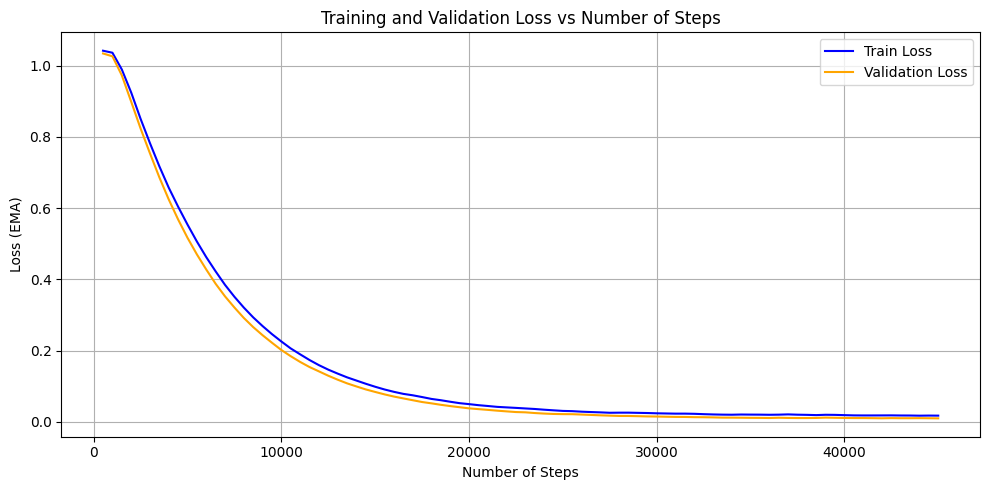

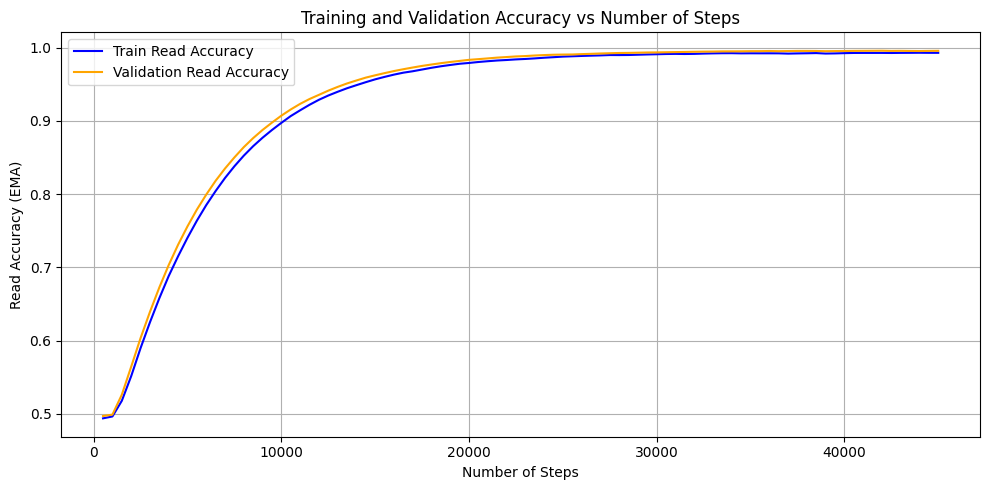

In [10]:
# whole fine tune loss and accuracy curves
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune","models")
result_dirs = ["5000_bacterial_benchmark_finetuned_45000"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))

log = os.path.join(dirs_[0],"log.csv")
out_path = os.path.join(project_root,"..","Reports","Final Report","images")
loss_out = os.path.join(out_path,"whole_model_finetune_loss.svg")
acc_out = os.path.join(out_path,"whole_model_finetune_acc.svg")
plot_loss_curve(log,loss_out)
plot_accuracy_curve(log,acc_out)


In [3]:
# COUNT PARAMETERS

import torch
from main.models.lora.model import SACallLoRA
from main.models.lora.modules import LoRAOptions

# bacterial benchmark
model = SACallLoRA(
            d_model=256,
            d_ff=1024,
            n_head=8,
            num_encoder_layers=6,
            device=torch.device("cuda"),
        )

print(f"Bacterial Benchmark: {model.count_parameters()}")
# freeze all parameters
for param in model.parameters():
    param.requires_grad = False

# unfreeze decoder FC params
for param in model.fc.parameters():
    param.requires_grad = True

print(f"Decoder Finetune: {model.count_parameters()}")

for param in model.parameters():
    param.requires_grad = False
model.bitfit()
print(f"BitFit Finetune: {model.count_parameters()}")

# freeze all parameters
for rank in [1,2,4,8,16]:
    # freeze all parameters
    for param in model.parameters():
        param.requires_grad = False
    model.finetune(LoRAOptions(q=True,k=True,v=False,attn_out=False,ffn=False,rank=rank),overwrite=True)
    print(f"LoRA rank {rank}: {model.count_parameters()}")


Bacterial Benchmark: 4833669
Decoder Finetune: 1285
BitFit Finetune: 16896
LoRA rank 1: 6144
LoRA rank 2: 12288
LoRA rank 4: 24576
LoRA rank 8: 49152
LoRA rank 16: 98304


In [32]:
# WHOLE MODEL
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["5000_bacterial_benchmark_finetuned_45000","whole_model_combined"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
constraints=[]

results=generate_results(result_dirs=dirs_,columns=["Name","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],constraints=constraints)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

# DECODER MODEL
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["5000_images_model_decoder_finetune_45000","decoder_combined"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
constraints=[]

results=generate_results(result_dirs=dirs_,columns=["Name","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],constraints=constraints)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

# LoRA Rank 1 with and without constraints
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["5000_images_model_finetune_rank_1_45000","lora_1_combined"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
constraints=[]

results=generate_results(result_dirs=dirs_,columns=["Name","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],constraints=constraints)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

# LoRA Rank 2 with and without constraints
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["5000_images_model_finetune_rank_2_45000","lora_2_combined"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
constraints=[]

results=generate_results(result_dirs=dirs_,columns=["Name","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],constraints=constraints)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

# LoRA Rank 4 with and without constraints
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["5000_images_model_finetune_rank_4_45000","lora_4_combined"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
constraints=[]

results=generate_results(result_dirs=dirs_,columns=["Name","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],constraints=constraints)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

# LoRA Rank 8 with and without constraints
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["5000_images_model_finetune_rank_8_45000","lora_8_combined"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
constraints=[]

results=generate_results(result_dirs=dirs_,columns=["Name","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],constraints=constraints)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))

# LoRA Rank 16 with and without constraints
# finetune TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["5000_images_model_finetune_rank_16_45000","lora_16_combined"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
constraints=[]

results=generate_results(result_dirs=dirs_,columns=["Name","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],constraints=constraints)
formatting_options = FormattingOptions(multirow=True,row_colours={0:"blue!15"},midrule=True)
print(generate_latex(results,formatting_options))


\multirow{2}{*}{EBI.jp2} & 94.88\cellcolor{blue!15} & 97.51\cellcolor{blue!15} & 95.73\cellcolor{blue!15} & 98.23\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 0.85\cellcolor{blue!15} & 0.00\cellcolor{blue!15} \\
 & 94.95 & 97.50 & 95.73 & 98.23 & 0.00 & 0.85 & 0.00 \\
\midrule
\multirow{2}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & 93.70\cellcolor{blue!15} & 94.57\cellcolor{blue!15} & 95.73\cellcolor{blue!15} & 98.23\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 0.85\cellcolor{blue!15} & 0.00\cellcolor{blue!15} \\
 & 93.75 & 94.58 & 95.73 & 98.23 & 0.00 & 0.86 & 0.00 \\
\midrule
\multirow{2}{*}{View\_huff3.cd} & 95.77\cellcolor{blue!15} & 99.81\cellcolor{blue!15} & 96.58\cellcolor{blue!15} & 99.12\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 0.00\cellcolor{blue!15} & 0.00\cellcolor{blue!15} \\
 & 95.81 & 99.81 & 96.58 & 99.12 & 0.00 & 0.00 & 0.00 \\
\midrule
\multirow{2}{*}{watsoncrick.pdf} & 94.81\cellcolor{blue!15} & 97.33\cellcolor{blue!15} & 94.87\cellcolor{blue!15} & 98.21\cellcolor{

In [10]:
# GENERATE TORCH PROFILING TABLES
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune","models")
result_dirs = ["default","5000_images_model_decoder_finetune_45000","5000_bacterial_benchmark_finetuned_45000","5000_images_model_finetune_rank_1_45000","5000_images_model_finetune_rank_2_45000","5000_images_model_finetune_rank_4_45000","5000_images_model_finetune_rank_8_45000","5000_images_model_finetune_rank_16_45000"]
names = ["-","Decoder","Whole Model","LoRA Rank 1","LoRA Rank 2","LoRA Rank 4","LoRA Rank 8","LoRA Rank 16"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
model_dirs = {n:d for (n,d) in list(zip(names,dirs_))}

print(generate_profiling_table(model_dirs))

\multirow{6}{*}{-} & \textbf{Forward Pass} & \textbf{1} & \textbf{11.579} & \textbf{113.641} & \textbf{48.0} & \textbf{7.467} \\
& \quad Convolutional Encoder & 1 & 1.060 & 0.949 & 0.0 & 0.134 \\
& \quad Positional Encoding & 1 & 0.221 & 0.326 & 0.0 & 0.042 \\
& \quad Transformer Encoder & 6 & 9.411 & 111.987 & 48.0 & 7.257 \\
& \quad Linear Decoder & 1 & 0.274 & 0.375 & 0.0 & 0.034 \\
& \textbf{Backwards pass} & \textbf{1} & \textbf{19.009} & \textbf{0.002} & \textbf{-48.0} & \textbf{-7.512} \\
\midrule
\multirow{6}{*}{Decoder} & \textbf{Forward Pass} & \textbf{1} & \textbf{10.758} & \textbf{112.408} & \textbf{0.0} & \textbf{0.034} \\
& \quad Convolutional Encoder & 1 & 0.982 & 0.932 & 0.0 & 0.034 \\
& \quad Positional Encoding & 1 & 0.207 & 0.317 & 0.0 & 0.034 \\
& \quad Transformer Encoder & 6 & 8.677 & 110.784 & 0.0 & 0.000 \\
& \quad Linear Decoder & 1 & 0.272 & 0.370 & 0.0 & 0.001 \\
& \textbf{Backwards pass} & \textbf{1} & \textbf{1.925} & \textbf{0.002} & \textbf{0.0} & \textbf

In [15]:
# DATA REGIME TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["10000_images_model_finetune_rank_4_45000","5000_images_model_finetune_rank_4_45000","1000_images_model_finetune_rank_4_45000","100_images_model_finetune_rank_4_45000","10_images_model_finetune_rank_4_45000","1_images_model_finetune_rank_4_45000","lora_rank_4_150_reads_45000","lora_rank_4_100_reads_45000","lora_rank_4_50_reads_45000","lora_rank_4_25_reads_45000","lora_rank_4_10_reads_45000","lora_rank_4_5_reads_45000","lora_rank_4_4_reads_45000","lora_rank_4_3_reads_45000","lora_rank_4_2_reads_45000","lora_rank_4_1_reads_45000"][::-1]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
number_of_reads = [1,2,3,4,5,10,25,50,100,150,192,1914,18930,187165,933902,1866798]
number_of_images=["N/A","N/A","N/A","N/A","N/A","N/A","N/A","N/A","N/A","N/A","1","10","100","1000","5000","10000"]
results=generate_results(result_dirs=dirs_,columns=["Name","number_of_reads","number_of_images","Mean Homopolymers Success","Mean Homopolymers Fail","Mean Length Success","Mean Length Fail","Mean KL Success","Mean KL Fail","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],number_of_reads=number_of_reads,number_of_images=number_of_images)
formatting_options = FormattingOptions(multirow=True,row_colours={},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{16}{*}{EBI.jp2} & 1 & N/A & 1.83 & 3.91 & 109.39 & 100.02 & 0.0074 & 0.0304 & 44.92 & 71.08 & 89.74 & 95.45 & 1.82 & 0.00 & 1.82 \\
 & 2 & N/A & 1.79 & 3.85 & 109.38 & 99.37 & 0.0072 & 0.0289 & 45.16 & 73.45 & 89.74 & 95.50 & 1.80 & 0.00 & 1.82 \\
 & 3 & N/A & 1.80 & 3.75 & 111.30 & 101.04 & 0.0070 & 0.0285 & 48.15 & 76.37 & 90.60 & 95.54 & 1.80 & 0.00 & 1.77 \\
 & 4 & N/A & 1.73 & 3.62 & 112.72 & 97.44 & 0.0071 & 0.0379 & 59.25 & 86.70 & 91.45 & 96.36 & 1.80 & 0.00 & 0.93 \\
 & 5 & N/A & 1.39 & 2.74 & 112.86 & 87.74 & 0.0066 & 0.0449 & 61.74 & 92.10 & 92.31 & 97.25 & 0.93 & 0.00 & 0.90 \\
 & 10 & N/A & 1.09 & 2.76 & 113.27 & 81.62 & 0.0066 & 0.0620 & 70.71 & 94.27 & 93.16 & 97.41 & 0.90 & 0.00 & 0.88 \\
 & 25 & N/A & 0.69 & 1.50 & 114.15 & 54.98 & 0.0063 & 0.1195 & 79.32 & 97.11 & 94.02 & 98.26 & 0.00 & 0.00 & 0.00 \\
 & 50 & N/A & 0.54 & 1.43 & 114.44 & 52.40 & 0.0063 & 0.1283 & 83.97 & 97.39 & 94.87 & 99.10 & 0.00 & 0.00 & 0.00 \\
 & 100 & N/A & 0.39 & 1.01 & 114.91 & 42.8

{'EBI': [['71.08', '89.74', '44.92'], ['73.45', '89.74', '45.16'], ['76.37', '90.60', '48.15'], ['86.70', '91.45', '59.25'], ['92.10', '92.31', '61.74'], ['94.27', '93.16', '70.71'], ['97.11', '94.02', '79.32'], ['97.39', '94.87', '83.97'], ['97.77', '94.87', '88.22'], ['97.96', '95.73', '90.13'], ['97.99', '95.73', '91.47'], ['98.29', '96.58', '95.41'], ['98.39', '96.58', '96.59'], ['98.38', '96.58', '96.46'], ['98.38', '96.58', '96.51'], ['98.41', '96.58', '96.44']], 'MLK_excerpt_VBR_45-85': [['65.84', '89.74', '43.31'], ['68.09', '89.74', '43.71'], ['70.86', '90.60', '46.43'], ['82.47', '91.45', '58.62'], ['87.92', '92.31', '61.04'], ['90.51', '93.16', '70.20'], ['93.84', '94.02', '78.64'], ['94.43', '94.87', '82.85'], ['95.11', '94.87', '87.29'], ['95.30', '95.73', '88.89'], ['95.35', '95.73', '90.75'], ['95.99', '96.58', '94.83'], ['96.19', '96.58', '95.77'], ['96.19', '96.58', '95.78'], ['96.15', '96.58', '95.76'], ['96.19', '96.58', '95.64']], 'View_huff3.cd': [['78.62', '89.74'

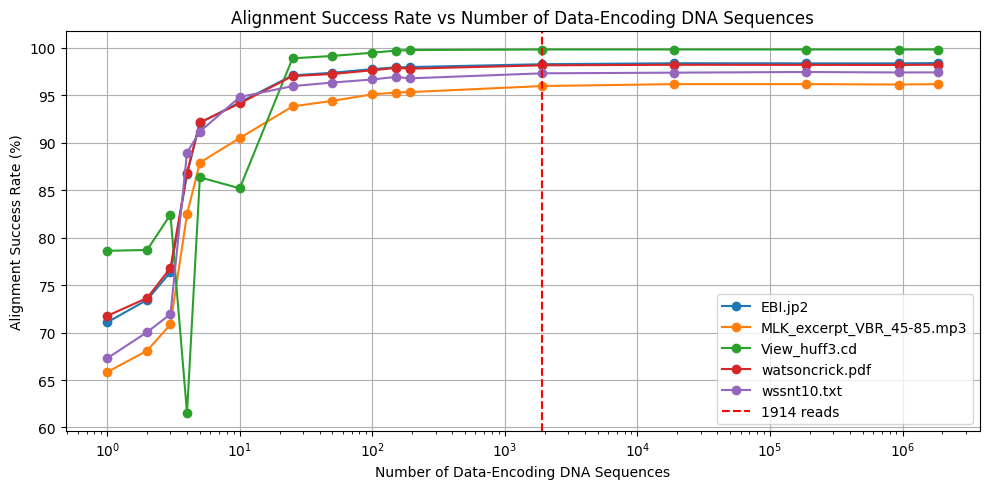

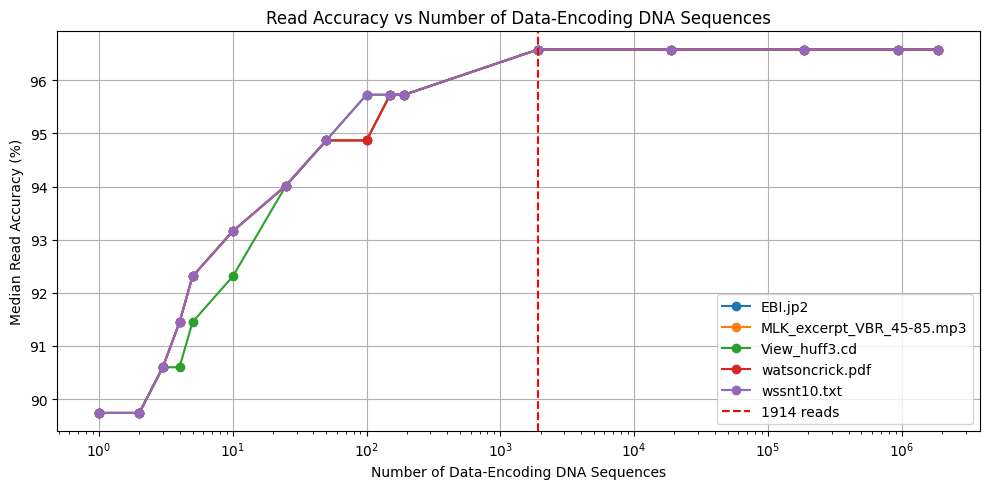

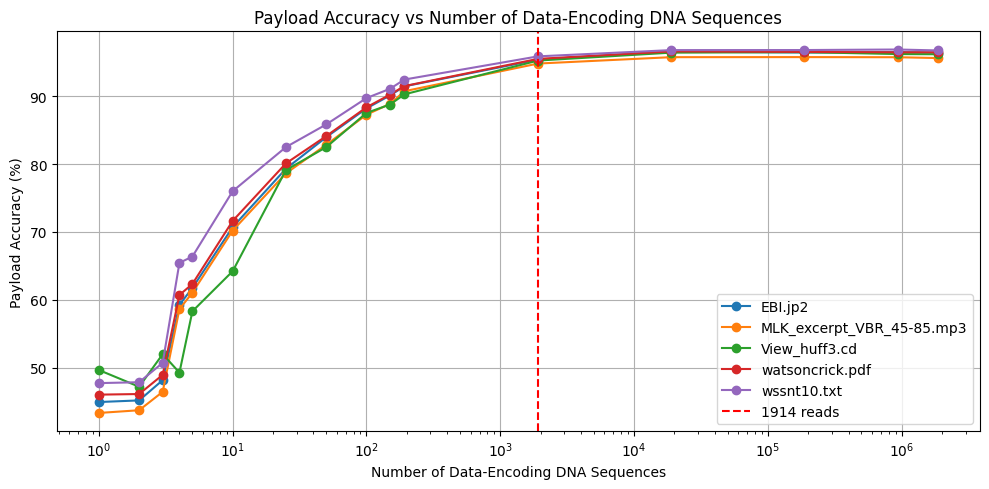

In [5]:
# DATA REGIME GRAPH
from matplotlib.ticker import MaxNLocator


number_of_reads = [1,2,3,4,5,10,25,50,100,150,192,1914,18930,187165,933902,1866798]
number_of_images=["N/A","N/A","N/A","N/A","N/A","N/A","N/A","N/A","N/A","1","10","100","1000","5000","10000"]
result_dirs = ["10000_images_model_finetune_rank_4_45000","5000_images_model_finetune_rank_4_45000","1000_images_model_finetune_rank_4_45000","100_images_model_finetune_rank_4_45000","10_images_model_finetune_rank_4_45000","1_images_model_finetune_rank_4_45000","lora_rank_4_150_reads_45000","lora_rank_4_100_reads_45000","lora_rank_4_50_reads_45000","lora_rank_4_25_reads_45000","lora_rank_4_10_reads_45000","lora_rank_4_5_reads_45000","lora_rank_4_4_reads_45000","lora_rank_4_3_reads_45000","lora_rank_4_2_reads_45000","lora_rank_4_1_reads_45000"][::-1]
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
results=generate_results(result_dirs=dirs_,columns=["Alignment Success Rate","Median Read Accuracy","Payload Accuracy"])
print(results)

files_to_names = {"EBI":"EBI.jp2","MLK_excerpt_VBR_45-85":"MLK_excerpt_VBR_45-85.mp3",'View_huff3.cd':'View_huff3.cd','watsoncrick':'watsoncrick.pdf','wssnt10':'wssnt10.txt'}
out_path = os.path.join(project_root,"..","Reports","Final Report","images")
# alignment succ rate
plt.figure(figsize=(10, 5))
for file_name, vals in results.items():
    alignment_rates = [float(r[0]) for r in vals]
    plt.plot(number_of_reads, alignment_rates, marker='o', label=files_to_names[file_name])

plt.axvline(x=1914, color='red', linestyle='--', linewidth=1.5, label='1914 reads')
plt.xscale('log')
plt.xlabel('Number of Data-Encoding DNA Sequences')
plt.ylabel('Alignment Success Rate (%)')
plt.title('Alignment Success Rate vs Number of Data-Encoding DNA Sequences')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(out_path, "regime_alignment.png"), format="png")
plt.show()

# median read acc
plt.figure(figsize=(10, 5))
for file_name, vals in results.items():
    alignment_rates = [float(r[1]) for r in vals]
    plt.plot(number_of_reads, alignment_rates, marker='o', label=files_to_names[file_name])

plt.axvline(x=1914, color='red', linestyle='--', linewidth=1.5, label='1914 reads')
plt.xscale('log')
plt.xlabel('Number of Data-Encoding DNA Sequences')
plt.ylabel('Median Read Accuracy (%)')
plt.title('Read Accuracy vs Number of Data-Encoding DNA Sequences')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(out_path, "regime_accuracy.png"), format="png")
plt.show()

# payload accuracy
plt.figure(figsize=(10, 5))
for file_name, vals in results.items():
    alignment_rates = [float(r[2]) for r in vals]
    plt.plot(number_of_reads, alignment_rates, marker='o', label=files_to_names[file_name])

plt.axvline(x=1914, color='red', linestyle='--', linewidth=1.5, label='1914 reads')
plt.xscale('log')
plt.xlabel('Number of Data-Encoding DNA Sequences')
plt.ylabel('Payload Accuracy (%)')
plt.title('Payload Accuracy vs Number of Data-Encoding DNA Sequences')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(out_path, "regime_payload_accuracy.png"), format="png")
plt.show()

In [29]:
# DATA REGIME TABLE ACROSS ALL LoRA RANKS
# DATA REGIME TABLE
ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["100_images_model_finetune_rank_1_45000","100_images_model_finetune_rank_2_45000","100_images_model_finetune_rank_4_45000","100_images_model_finetune_rank_8_45000","100_images_model_finetune_rank_16_45000"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
rank=["1","2","4","8","16"]

results=generate_results(result_dirs=dirs_,columns=["Name","rank","Payload Accuracy","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],rank=rank)
formatting_options = FormattingOptions(multirow=True,row_colours={},midrule=True)
print(generate_latex(results,formatting_options))


\multirow{5}{*}{EBI.jp2} & 1 & 90.44 & 98.10 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 2 & 94.64 & 98.26 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 4 & 96.59 & 98.39 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 8 & 97.31 & 98.43 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 16 & 97.58 & 98.43 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
\midrule
\multirow{5}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & 1 & 89.50 & 95.43 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 2 & 93.94 & 95.91 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 4 & 95.77 & 96.19 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 8 & 96.68 & 96.31 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 16 & 97.13 & 96.31 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
\midrule
\multirow{5}{*}{View\_huff3.cd} & 1 & 89.94 & 99.72 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 2 & 94.20 & 99.78 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 4 & 96.44 & 99.84 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 8 & 96.81 & 99.84 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & 16 & 97.2

In [14]:
#FINETUNE from checkpoint

ROOT_RESULTS_DIR = os.path.join(project_root,"..","experiments","finetune")
result_dirs = ["lora_rank_4_from_20000_for_45000","lora_rank_4_from_40000_for_45000","lora_rank_4_from_60000_for_45000","lora_rank_4_from_80000_for_45000","lora_rank_4_from_100000_for_45000","lora_rank_4_from_120000_for_45000"]
dirs_ = list(map(lambda y: os.path.join(ROOT_RESULTS_DIR,y),result_dirs))
data=["-","-","-","-","-","-"]

results=generate_results(result_dirs=dirs_,columns=["Name","data","Mean Homopolymers per Sequence","Mean Length Success","Mean Length Fail","Mean KL Success","Mean KL Fail","Alignment Success Rate","Median Read Accuracy", "Median Match Rate", "Median Mismatch Rate", "Median Insertion Rate","Median Deletion Rate"],data=data)
formatting_options = FormattingOptions(multirow=True,row_colours={},midrule=True)
print(generate_latex(results,formatting_options))

\multirow{6}{*}{EBI.jp2} & - & 0.32 & 114.17 & 34.24 & 0.0062 & 0.1385 & 98.27 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & - & 0.21 & 115.28 & 31.97 & 0.0062 & 0.1454 & 98.37 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & - & 0.25 & 114.98 & 33.34 & 0.0063 & 0.1526 & 98.34 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & - & 0.17 & 115.37 & 32.52 & 0.0062 & 0.1249 & 98.39 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & - & 0.17 & 115.30 & 32.97 & 0.0063 & 0.1578 & 98.31 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & - & 0.19 & 114.99 & 32.82 & 0.0064 & 0.1790 & 98.30 & 96.58 & 100.00 & 0.00 & 0.00 & 0.00 \\
\midrule
\multirow{6}{*}{MLK\_excerpt\_VBR\_45-85.mp3} & - & 0.32 & 114.02 & 61.13 & 0.0063 & 0.0936 & 95.97 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & - & 0.22 & 115.15 & 61.79 & 0.0062 & 0.0916 & 96.00 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & - & 0.26 & 114.82 & 61.19 & 0.0063 & 0.1004 & 96.03 & 95.73 & 100.00 & 0.00 & 0.00 & 0.00 \\
 & - & 0.18 & 115.21 & 61.77 & 0.0063 & 0.0840 & 96.09 & 9

In [ ]:
# count length for minimap

default_dir = os.path.join(project_root,"..","experiments","finetune","default")
files = os.listdir(default_dir)
less_100 = 0
geq_100 = 0
g_117 = 0
for f in files:
    file_path = os.path.join(default_dir,f)
    basecalls = os.path.join(file_path,"basecalls.fastq")
    for rec in SeqIO.parse(basecalls,"fastq"):
        seq = str(rec.seq)
        if len(seq) >= 100:
            geq_100 +=1
            if len(seq) > 117:
                g_117 += 1
        else:
            less_100 +=1

print(geq_100)
print(less_100)
print(g_117)


115620
37742
0
